# evans2013

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su
from sympy.physics.units.quantities import Quantity

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_rhoH(T_leaf, rhoH25, T_H):
    return rhoH25 * np.exp(T_H * (((1) / (273 + T_leaf)) - ((1) / (298))))

def _derived_D(T_leaf, D0, E_D, R):
    return D0 * np.exp((- (E_D)) / (R * (273 + T_leaf)))

def _derived_g_liq(l, Sc, rhoH, D):
    return (rhoH * D * Sc) / (l * 0.000001)

def _derived_g_mem(T_leaf, R, gmem25, E_mem):
    return gmem25 * np.exp((((T_leaf) - (25)) * E_mem) / (R * 298 * (273 + T_leaf)))

def _derived_gm(g_liq, g_mem):
    return (g_liq * g_mem) / (g_liq + g_mem)

def _derived_gm_lin(T_leaf, gm25_lin, a_lin, b_lin):
    return gm25_lin * (a_lin + b_lin * T_leaf)

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("T_leaf", 25, unit=Quantity("celsius", abbrev="°C"), display_name="T_leaf", tex_name="T", slider=Slider(min="5", max="45", step="0.5"))
    m.add_parameter("rhoH25", 33.06, unit=su.mol/(su.meter**3*su.bar), display_name="rhoH25", tex_name="\\rho H_{25}")
    m.add_parameter("T_H", 2400, unit=su.kelvin, display_name="T_H", tex_name="T_H")
    m.add_parameter("D0", 0.00000181, unit=su.meter**2/su.second, display_name="D0", tex_name="D_0")
    m.add_parameter("E_D", 16900, unit=su.joule/su.mol, display_name="E_D", tex_name="E_D")
    m.add_parameter("R", 8.314, unit=su.joule/(su.kelvin*su.mol), display_name="R", tex_name="\\mathcal{R}")
    m.add_parameter("l", 1.5, unit=su.meter*su.micro, display_name="l", tex_name="l", slider=Slider(min="0.5", max="5", step="0.05"))
    m.add_parameter("Sc", 22, unit=None, display_name="Sc", tex_name="S_c", slider=Slider(min="5", max="40", step="0.5"))
    m.add_parameter("gmem25", 1.03, unit=su.mol/(su.meter**2*su.second*su.bar), display_name="gmem25", tex_name="g_{mem,25}", slider=Slider(min="0.1", max="5", step="0.01"))
    m.add_parameter("E_mem", 50000, unit=su.joule/su.mol, display_name="E_mem", tex_name="E", slider=Slider(min="0", max="100000", step="1000"))
    m.add_parameter("gm25_lin", 0.57, unit=su.mol/(su.meter**2*su.second*su.bar), display_name="gm25_lin", tex_name="g_{m,25}", slider=Slider(min="0.05", max="2", step="0.01"))
    m.add_parameter("a_lin", -0.26, unit=None, display_name="a_lin", tex_name="a")
    m.add_parameter("b_lin", 0.051, unit=1/Quantity("celsius", abbrev="°C"), display_name="b_lin", tex_name="b")
    m.add_derived("rhoH", _derived_rhoH, args=["T_leaf", "rhoH25", "T_H"], unit=su.mol/(su.meter**3*su.bar), display_name="rhoH", tex_name="\\rho H")
    m.add_derived("D", _derived_D, args=["T_leaf", "D0", "E_D", "R"], unit=su.meter**2/su.second, display_name="D", tex_name="D")
    m.add_derived("g_liq", _derived_g_liq, args=["l", "Sc", "rhoH", "D"], unit=su.mol/(su.meter**2*su.second*su.bar), display_name="g_liq", tex_name="g_{liq}")
    m.add_derived("g_mem", _derived_g_mem, args=["T_leaf", "R", "gmem25", "E_mem"], unit=su.mol/(su.meter**2*su.second*su.bar), display_name="g_mem", tex_name="g_{mem}")
    m.add_derived("gm", _derived_gm, args=["g_liq", "g_mem"], unit=su.mol/(su.meter**2*su.second*su.bar), display_name="gm", tex_name="g_m")
    m.add_derived("gm_lin", _derived_gm_lin, args=["T_leaf", "gm25_lin", "a_lin", "b_lin"], unit=su.mol/(su.meter**2*su.second*su.bar), display_name="gm_lin", tex_name="g_{m,lin}")
    return m


## Figure 5: linear temperature response of gm, normalised to 25 °C (2 % O₂ regression)

In [3]:
tables = {}

# Scan t
to_scan = pd.DataFrame({"T_leaf": np.linspace(12, 42, 301), "gm25_lin": 1})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["gm_lin"]].isna().any(axis=None)
tables["t"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "gm_lin": frame["gm_lin"].to_numpy(),
}

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 7890.58it/s]

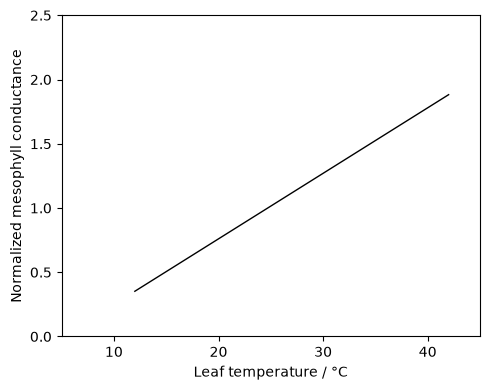

In [4]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["t"]["x"], tables["t"]["gm_lin"], color="black", lw=1)
ax0.set_xlabel("Leaf temperature / °C")
ax0.set_ylabel("Normalized mesophyll conductance")
ax0.set_xlim(5, 45)
ax0.set_ylim(0, 2.5)
ax0.set_xticks([10,20,30,40])
ax0.set_yticks([0,0.5,1,1.5,2,2.5])
plt.tight_layout()
plt.show()

## Figure 7: modelled conductances through the liquid phase and membranes, and gm

In [5]:
tables = {}

# Scan t
to_scan = pd.DataFrame({"T_leaf": np.linspace(10, 45, 351)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["g_liq","g_mem","gm"]].isna().any(axis=None)
tables["t"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "g_liq": frame["g_liq"].to_numpy(),
    "g_mem": frame["g_mem"].to_numpy(),
    "gm": frame["gm"].to_numpy(),
}

  0%|          | 0/351 [00:00<?, ?it/s]

100%|██████████| 351/351 [00:00<00:00, 7998.53it/s]

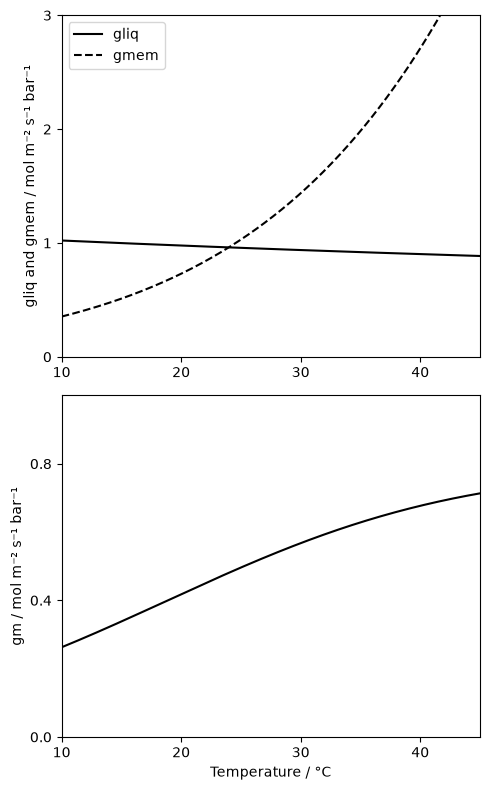

In [6]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(5, 8), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["t"]["x"], tables["t"]["g_liq"], color="black", label="gliq")
ax0.plot(tables["t"]["x"], tables["t"]["g_mem"], color="black", ls="--", label="gmem")
ax0.set_ylabel("gliq and gmem / mol m⁻² s⁻¹ bar⁻¹")
ax0.set_xlim(10, 45)
ax0.set_ylim(0, 3)
ax0.set_xticks([10,20,30,40])
ax0.set_yticks([0,1,2,3])
ax0.legend()
ax1 = axs[1, 0]
ax1.plot(tables["t"]["x"], tables["t"]["gm"], color="black")
ax1.set_xlabel("Temperature / °C")
ax1.set_ylabel("gm / mol m⁻² s⁻¹ bar⁻¹")
ax1.set_xlim(10, 45)
ax1.set_ylim(0, 1)
ax1.set_xticks([10,20,30,40])
ax1.set_yticks([0,0.4,0.8])
plt.tight_layout()
plt.show()